# Titanic EDA: Completed reference

**Question:** How does survival vary by passenger class? What should we investigate after the first plot?

All code and outputs are supplied. Use this as your teaching reference or recovery copy.

The paired notebooks use the same sections. Open the scaffold for class and keep the completed version in another tab.

Data: the bundled seaborn Titanic subset. See [the data dictionary](../data_dictionary.qmd) and [source notes](../sources.qmd).


## Setup

Run this cell before class. The dataset loads from the project folder without a download.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Open the project folder in Positron and select its .venv interpreter.
# Support kernels starting in the project root or in notebooks/.
ROOT = Path.cwd()
if not (ROOT / "data/titanic.csv").is_file():
    ROOT = ROOT.parent
if not (ROOT / "data/titanic.csv").is_file():
    raise FileNotFoundError("Open the project folder, then run this notebook again.")

titanic = pd.read_csv(ROOT / "data/titanic.csv")
sns.set_theme(style="whitegrid", context="talk")


## The records

What does one row represent? Which columns can help us compare survival across passenger classes?


In [2]:
titanic.head()


,row_id,survived,pclass,sex,age,fare,sibsp,parch,embarked
0,0,0,3,male,22.0,7.2500,1,0,S
1,1,1,1,female,38.0,71.2833,1,0,C
2,2,1,3,female,26.0,7.9250,0,0,S
3,3,1,1,female,35.0,53.1000,1,0,S
4,4,0,3,male,35.0,8.0500,0,0,S


**Interpretation:** One row represents one passenger in this 891-record subset. This is not the complete Titanic manifest.


## Available information

Are the fields we need complete? Age and embarkation may matter for later questions.


In [3]:
print(f"Passenger records: {len(titanic):,}")
titanic.isna().sum()


Passenger records: 891


row_id        0
survived      0
pclass        0
sex           0
age         177
fare          0
sibsp         0
parch         0
embarked      2
dtype: int64

**Interpretation:** `survived`, `pclass`, and `sex` are complete. `age` has 177 missing values and `embarked` has 2. All 891 records contribute to the comparisons below.


## Optional warmup: the fare distribution

What do you notice? What would you ask next? This matches the opening slide and can be skipped during the seven-minute demonstration.


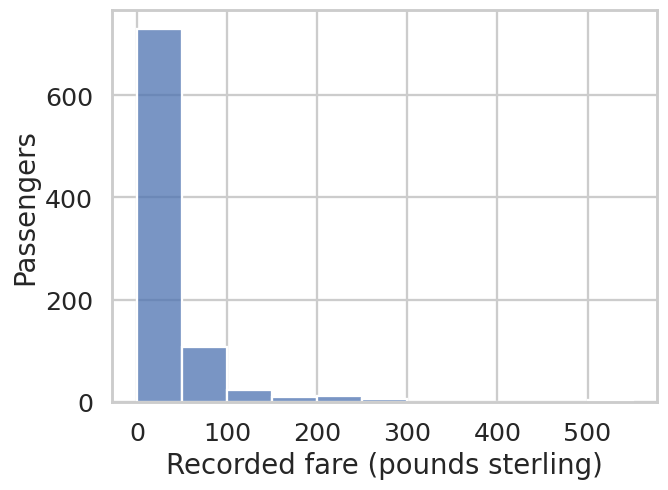

In [4]:
sns.histplot(data=titanic, x="fare", bins=range(0, 551, 50))
plt.xlabel("Recorded fare (pounds sterling)")
plt.ylabel("Passengers")
plt.tight_layout()
plt.show()


**Interpretation:** Most recorded fares are in the lower bins, with a long right tail. A comparison by class would be a reasonable next question.


## First question: how many survivors in each class?

Begin with a count. What does this view leave unresolved if we want to compare survival proportions?


pclass
1    136
2     87
3    119
dtype: int64

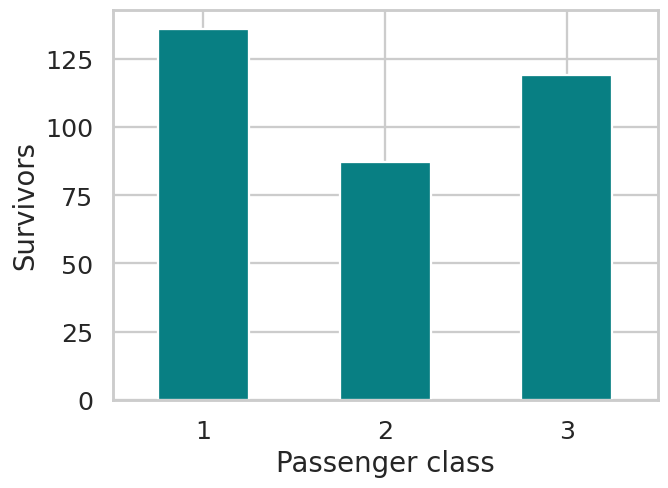

In [5]:
survivors = titanic.loc[titanic["survived"].eq(1)]
counts = survivors.groupby("pclass").size()
display(counts)
ax = counts.plot.bar(rot=0, color="#087F83")
ax.set(xlabel="Passenger class", ylabel="Survivors")
plt.tight_layout()
plt.show()


**Interpretation:** The survivor counts are 136, 87, and 119. The class sizes differ, so the counts alone do not answer the proportion question.


## Follow-up: what proportion survived?

Use all passengers in each class as the denominator. For complete 0/1 data, the mean equals the proportion of ones.


,survivors,passengers,survival_rate
pclass,,,
1,136,216,0.630
2,87,184,0.473
3,119,491,0.242


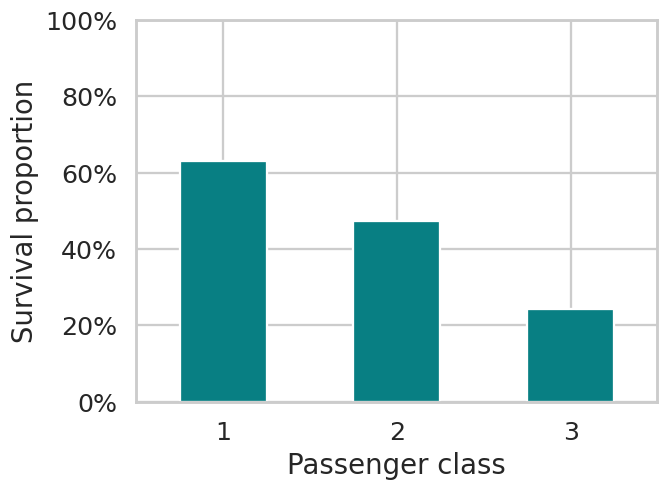

In [6]:
class_summary = titanic.groupby("pclass")["survived"].agg(
    survivors="sum", passengers="size", survival_rate="mean"
)
display(class_summary.round(3))
ax = class_summary["survival_rate"].plot.bar(rot=0, color="#087F83")
ax.set(xlabel="Passenger class", ylabel="Survival proportion", ylim=(0, 1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout()
plt.show()


**Interpretation:** The proportions are 63.0% (136/216), 47.3% (87/184), and 24.2% (119/491). The next question asks whether that aggregate pattern looks similar within sex categories.


## Another question: does the pattern look similar within sex categories?

Keep the class comparison and add recorded sex through color. Predict what might change before running the cell.


survivors  passengers  survival_rate
pclass sex                                         
1      female         91          94          0.968
       male           45         122          0.369
2      female         70          76          0.921
       male           17         108          0.157
3      female         72         144          0.500
       male           47         347          0.135

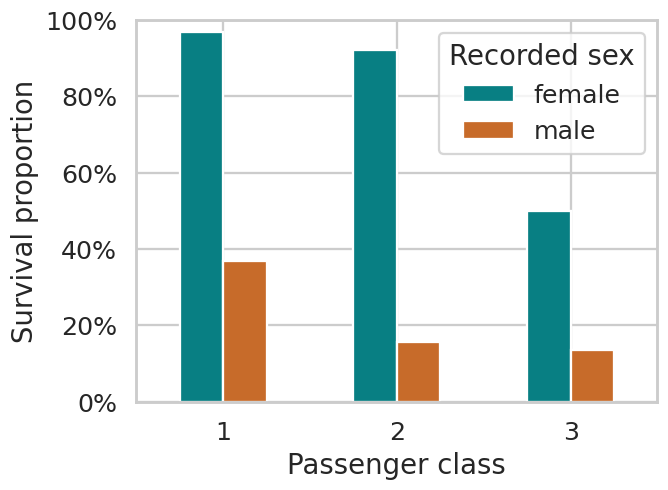

In [7]:
group_summary = titanic.groupby(["pclass", "sex"])["survived"].agg(
    survivors="sum", passengers="size", survival_rate="mean"
)
display(group_summary.round(3))
rates = group_summary["survival_rate"].unstack("sex")
ax = rates.plot.bar(rot=0, color=["#087F83", "#C76B2A"])
ax.set(xlabel="Passenger class", ylabel="Survival proportion", ylim=(0, 1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend(title="Recorded sex")
plt.tight_layout()
plt.show()


**Interpretation:** First-class survival proportions exceed third-class proportions within both recorded categories. Female survival proportions exceed male proportions within each class. These are descriptive associations in the passenger subset, not isolated causal effects.


## Where would we go next?

Does age help explain variation within a class-by-sex group? How should we handle the missing ages?

What could fare, family size, and embarkation add to our understanding of passenger profiles?

Keep these questions open for Day 2. Today the reusable move is to explain why the next view helps answer the next question.
